# P04: the first CNN, trained longer and with batch norm

ADR 0007 found that the first CNN **underfits**: after 30 epochs its validation accuracy was still rising and its best
epoch was the last one. Two cheap ideas from that ADR:

- **Train longer** (100 epochs instead of 30).
- **Batch norm**: after each convolution, the values of each filter are rescaled over the batch (mean 0, spread 1) during
  training, and with statistics kept along the way when evaluating. Each layer then receives inputs of a steady scale, which
  usually lets a network learn faster.

ADR 0007 says to change one thing at a time. So we run the two changes **separately and together**, and compare them with
the first CNN of P03 (30 epochs, no batch norm), which is not run again:

| run | epochs | batch norm |
|---|---|---|
| `cnn_first` (P03) | 30 | no |
| `cnn_longer` | 100 | no |
| `cnn_batchnorm` | 30 | yes |
| `cnn_longer_batchnorm` | 100 | yes |

Everything else is identical: same data, same split, same seed (0), same training loop. To explore we use one seed per run
(`seeds=1`); the promising one is repeated with 5 seeds at the end. **The test set (museum B) is not used here** (ADR 0003).

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from deep_learning_project_waerniers_lamy_mahieddine.vision.utils import load_result, run_experiment, summary

REFERENCE = "cnn_first_2026-10-21_19-54-39"  # the first CNN of P03, not run again

BASE = {
    "model": "cnn",
    "image_size": 64,
    "conv_channels": [16, 32, 64],
    "kernel_size": 3,
    "batch_norm": False,
    "dropout": 0.0,
    "epochs": 30,
    "lr": 1e-3,
    "batch_size": 64,
    "weight_decay": 0.0,
    "seed": 0,
}

# Safety check: BASE is exactly the config of the reference run, so only the changes below can explain a difference.
reference = load_result(REFERENCE)
assert reference["config"] == BASE

RUNS = {
    "cnn_longer": {**BASE, "epochs": 100},
    "cnn_batchnorm": {**BASE, "batch_norm": True},
    "cnn_longer_batchnorm": {**BASE, "epochs": 100, "batch_norm": True},
}
outcomes = {}

## 1. Longer only

100 epochs instead of 30, about 7 minutes.

In [2]:
outcomes["cnn_longer"] = run_experiment("cnn_longer", RUNS["cnn_longer"], seeds=1)

23909 parameters | before training: loss 1.609 (ln 5 = 1.609), accuracy 19.5%
epoch   1 | train loss 1.506 acc 0.322 | val loss 1.555 acc 0.265
epoch   5 | train loss 1.343 acc 0.415 | val loss 1.413 acc 0.379
epoch  10 | train loss 1.200 acc 0.503 | val loss 1.268 acc 0.471
epoch  15 | train loss 1.119 acc 0.569 | val loss 1.183 acc 0.481
epoch  20 | train loss 1.081 acc 0.584 | val loss 1.160 acc 0.504
epoch  25 | train loss 1.072 acc 0.566 | val loss 1.155 acc 0.490
epoch  30 | train loss 1.041 acc 0.597 | val loss 1.145 acc 0.537
epoch  35 | train loss 1.051 acc 0.601 | val loss 1.164 acc 0.531
epoch  40 | train loss 1.028 acc 0.599 | val loss 1.143 acc 0.527
epoch  45 | train loss 0.968 acc 0.633 | val loss 1.099 acc 0.573
epoch  50 | train loss 0.959 acc 0.637 | val loss 1.120 acc 0.565
epoch  55 | train loss 0.960 acc 0.637 | val loss 1.125 acc 0.550
epoch  60 | train loss 0.949 acc 0.628 | val loss 1.148 acc 0.540
epoch  65 | train loss 0.872 acc 0.682 | val loss 1.069 acc 0.57

## 2. Batch norm only

30 epochs as before, with a batch norm after each convolution (it adds 224 weights).

In [3]:
outcomes["cnn_batchnorm"] = run_experiment("cnn_batchnorm", RUNS["cnn_batchnorm"], seeds=1)

24133 parameters | before training: loss 1.609 (ln 5 = 1.609), accuracy 19.5%
epoch   1 | train loss 1.441 acc 0.393 | val loss 1.481 acc 0.350
epoch   5 | train loss 1.150 acc 0.549 | val loss 1.228 acc 0.500
epoch  10 | train loss 1.138 acc 0.548 | val loss 1.226 acc 0.498
epoch  15 | train loss 1.410 acc 0.461 | val loss 1.579 acc 0.435
epoch  20 | train loss 1.032 acc 0.604 | val loss 1.206 acc 0.521
epoch  25 | train loss 1.023 acc 0.581 | val loss 1.211 acc 0.494
epoch  30 | train loss 0.927 acc 0.609 | val loss 1.172 acc 0.517

best validation accuracy 59.4% at epoch 21 (248 s)
saved results/cnn_batchnorm_2026-10-22_13-16-39.pkl and added a row to results/experiments.csv


## 3. Both

100 epochs with batch norm.

In [4]:
outcomes["cnn_longer_batchnorm"] = run_experiment("cnn_longer_batchnorm", RUNS["cnn_longer_batchnorm"], seeds=1)

24133 parameters | before training: loss 1.609 (ln 5 = 1.609), accuracy 19.5%
epoch   1 | train loss 1.441 acc 0.393 | val loss 1.481 acc 0.350
epoch   5 | train loss 1.150 acc 0.549 | val loss 1.228 acc 0.500
epoch  10 | train loss 1.138 acc 0.548 | val loss 1.226 acc 0.498
epoch  15 | train loss 1.410 acc 0.461 | val loss 1.579 acc 0.435
epoch  20 | train loss 1.032 acc 0.604 | val loss 1.206 acc 0.521
epoch  25 | train loss 1.023 acc 0.581 | val loss 1.211 acc 0.494
epoch  30 | train loss 0.927 acc 0.609 | val loss 1.172 acc 0.517
epoch  35 | train loss 0.906 acc 0.663 | val loss 1.235 acc 0.537
epoch  40 | train loss 0.731 acc 0.728 | val loss 1.021 acc 0.588
epoch  45 | train loss 0.769 acc 0.705 | val loss 1.170 acc 0.548
epoch  50 | train loss 0.994 acc 0.592 | val loss 1.413 acc 0.485
epoch  55 | train loss 0.888 acc 0.669 | val loss 1.370 acc 0.558
epoch  60 | train loss 0.662 acc 0.730 | val loss 1.140 acc 0.552
epoch  65 | train loss 0.664 acc 0.743 | val loss 1.163 acc 0.55

## 4. Learning curves

Three things to look at: does the validation accuracy keep rising or flatten, is the train accuracy catching up with it
(a growing gap means overfitting), and does the validation loss start rising again.

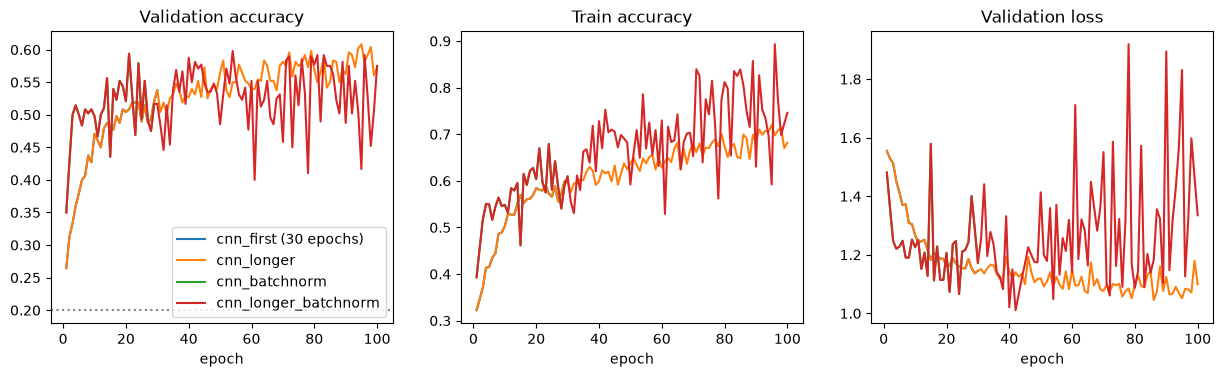

In [5]:
histories = {"cnn_first (30 epochs)": reference["history"]}
for name, outcome in outcomes.items():
    histories[name] = outcome["result"]["history"]

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for label, h in histories.items():
    epochs = range(1, len(h["val_acc"]) + 1)
    axes[0].plot(epochs, h["val_acc"], label=label)
    axes[1].plot(epochs, h["train_acc"], label=label)
    axes[2].plot(epochs, h["val_loss"], label=label)
axes[0].set_title("Validation accuracy")
axes[1].set_title("Train accuracy")
axes[2].set_title("Validation loss")
axes[0].axhline(0.2, color="grey", linestyle=":")
for ax in axes:
    ax.set_xlabel("epoch")
axes[0].legend()
plt.show()

## 5. The scores side by side

All four runs use seed 0, so they can be compared directly (`val_acc_mean` is only filled for runs repeated over several
seeds, such as `cnn_first`).

In [6]:
table = summary()
table[table["name"].str.startswith("cnn_")][
    ["name", "batch_norm", "epochs", "n_params", "best_epoch", "best_val_acc", "val_acc_mean", "seconds"]]

,name,batch_norm,epochs,n_params,best_epoch,best_val_acc,val_acc_mean,seconds
3,cnn_longer,False,100,23909,95,0.6083,NaN,574
5,cnn_longer,False,100,23909,95,0.6083,NaN,683
7,cnn_longer_batchnorm,True,100,24133,54,0.5979,NaN,822
8,cnn_longer_batchnorm,True,100,24133,54,0.5979,NaN,740
4,cnn_batchnorm,True,30,24133,21,0.5938,NaN,250
6,cnn_batchnorm,True,30,24133,21,0.5938,NaN,248
2,cnn_first,False,30,23909,30,0.5375,0.5358,129


In [7]:
confusions = {"cnn_first": reference["val_confusion"]}
confusions.update({name: outcome["confusion"] for name, outcome in outcomes.items()})
pd.DataFrame({name: {genre: c.loc[genre, genre] / c.loc[genre].sum() for genre in c.index}
              for name, c in confusions.items()}).round(2)

,cnn_first,cnn_longer,cnn_batchnorm,cnn_longer_batchnorm
cityscape,0.55,0.65,0.45,0.54
landscape,0.62,0.61,0.61,0.74
portrait,0.75,0.61,0.78,0.55
religious_painting,0.34,0.59,0.48,0.68
still_life,0.42,0.57,0.65,0.48


## 6. Repeat the promising run with 5 seeds

One seed is only a first look. Put the name of the run to confirm in `CONFIRM` (for example `"cnn_longer_batchnorm"`) and run
the cell: it repeats that config with 5 seeds, to compare with the 53.6% mean (std 0.8) of the first CNN. It takes about 5 times
as long as the run. Leave it at `None` until we have looked at the curves.

In [8]:
CONFIRM = None

if CONFIRM:
    run_experiment(CONFIRM + "_5seeds", RUNS[CONFIRM], seeds=5)

## What we see

Seed 0 for every run. "Swing" is how much the validation accuracy moves from one epoch to the next, over the last 10 epochs.

| run | best epoch | last epoch | mean of last 10 | at lowest val loss | train acc, last | swing |
|---|---|---|---|---|---|---|
| `cnn_first` (30 epochs) | 53.8% (epoch 30) | 53.8% | 51.1%* | 52.1% | 59.7% | 1.9 pts |
| `cnn_longer` (100) | **60.8%** (95) | 57.3% | **58.8%** | 58.3% | 68.2% | 2.2 pts |
| `cnn_batchnorm` (30) | 59.4% (21) | 51.7% | 52.2% | 57.9% | 60.9% | 6.3 pts |
| `cnn_longer_batchnorm` (100) | 59.8% (54) | 57.5% | 52.0% | 58.1% | 74.6% | 8.6 pts |

*the first CNN was still rising during those epochs, so this understates it.

- **Training longer is a real gain.** The curve is steady, and `cnn_longer` is 5 to 7 points above the first CNN on every
  smoother measure. Its validation loss is lowest at epoch 86 (1.05) and then rises slightly, and the gap between train and
  validation is 11 points at the end: the network has stopped underfitting and is starting to overfit.
- **Batch norm learns faster at first** (epoch 5: 50.0% on validation against 37.9%) **but makes the validation score erratic.**
  It jumps 6 to 9 points from one epoch to the next, so its best epochs are lucky peaks: a typical epoch (about 52%) is no
  better than the first CNN. Why it is unstable we have not tested.
- **Together, the two changes do not add up.** The combined run fits the training set best (74.6%) but overfits the most: its
  validation loss goes from 1.01 (epoch 42) up to 1.34.
- **Caveats.** One seed per run, about +/- 4.4 points of sampling uncertainty on 480 images, and "best epoch" is the best of many
  noisy epochs. The ranking among the three variants cannot be trusted from their best epochs alone. The notebook ran twice, so
  `experiments.csv` holds each run twice with identical numbers.
- **The CNN still cannot fit its training images** (68% train accuracy after 100 epochs), which suggests it is too small. Next
  (ADR 0008, `P05_cnn_deeper.ipynb`): a fourth convolution block.